# Text generator

This reports goal is to build a text generator neural network.

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow' 

import numpy as np
import keras
import sentencepiece as spm

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.12.0
Keras backend: tensorflow


In [2]:
with open('frankenstein.txt', 'r', encoding='utf-8-sig') as file:
    text = file.read()#.lower()

print(f"Text length: {len(text)} characters")
print(f"First 100 characters: {text[:100]}")

Text length: 438806 characters
First 100 characters: The Project Gutenberg eBook of Frankenstein; Or, The Modern Prometheus
    
This ebook is for the us


In [3]:
temp_file = 'frankenstein_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# Train SentencePiece model
vocab_size = 20000  # You can adjust this based on your needs
model_prefix = 'frankenstein_sp'


spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,  # Important for Finnish
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# Load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

# Test tokenization
test_text = "This is a test sentence to check the tokenizer."
tokens = sp.encode_as_pieces(test_text)
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁This', '▁is', '▁a', '▁test', '▁sentence', '▁to', '▁check', '▁the', '▁to', 'ken', 'iz', 'er', '.']
Vocabulary size: 20000


In [4]:
# Tokenize the text
seq_length = 64
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

# Create sequences
sequences = []
for i in range(0, len(pieces) - seq_length):
    # Input: first seq_length tokens, Target: next seq_length tokens (shifted by 1)
    sequences.append(pieces[i:i+seq_length+1])

# Convert to NumPy arrays
sequences = np.array(sequences)
inputs = sequences[:, :-1]  # All tokens except the last one
targets = sequences[:, 1:]  # All tokens except the first one

print(f"Number of sequences: {len(sequences)}")
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

# Split into training and validation sets
indices = np.arange(len(sequences))
np.random.shuffle(indices)

train_size = int(0.8 * len(sequences))
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_inputs, train_targets = inputs[train_indices], targets[train_indices]
val_inputs, val_targets = inputs[val_indices], targets[val_indices]

Total tokens: 89164
Number of sequences: 89100
Input shape: (89100, 64)
Target shape: (89100, 64)


In [5]:
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# Define model parameters
embed_dim = 256
num_heads = 4
ff_dim = 512
num_layers = 3

# Create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# Add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# Helper function to create causal attention mask
def create_causal_mask(size):
    """Create a causal attention mask to prevent looking at future tokens."""
    mask = 1 - np.triu(np.ones((size, size)), k=1)
    return mask  # Lower triangular matrix

# Transformer blocks
for _ in range(num_layers):
    # Multi-head attention with causal mask
    # Manually create causal mask since use_causal_mask parameter isn't available
    causal_mask = create_causal_mask(seq_length)

    # Apply attention with manual causal mask
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads
    )(x, x, attention_mask=causal_mask)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# Final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 256)   │  5,120,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 256)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 256)   │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 256)   │        512 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 256)   │    262,912 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 256)   │    262,912 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten

 Total params: 11,841,312 (45.17 MB)

 Trainable params: 11,841,312 (45.17 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
batch_size = 64
epochs = 10

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('frankenstein_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/10
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1381s 1s/step - accuracy: 0.1660 - loss: 5.3116 - val_accuracy: 0.2845 - val_loss: 3.8424 - learning_rate: 3.0000e-04
Epoch 2/10
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1404s 1s/step - accuracy: 0.4348 - loss: 2.7653 - val_accuracy: 0.6645 - val_loss: 1.5458 - learning_rate: 3.0000e-04
Epoch 3/10
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1400s 1s/step - accuracy: 0.7971 - loss: 0.9584 - val_accuracy: 0.9172 - val_loss: 0.4481 - learning_rate: 3.0000e-04
Epoch 4/10
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1398s 1s/step - accuracy: 0.9248 - loss: 0.3888 - val_accuracy: 0.9444 - val_loss: 0.2804 - learning_rate: 3.0000e-04
Epoch 5/10
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1395s 1s/step - accuracy: 0.9449 - loss: 0.2726 - val_accuracy: 0.9521 - val_loss: 0.2327 - learning_rate: 3.0000e-04
Epoch 6/10
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1393s 1s/step - accuracy: 0.9527 - loss: 0.2264 - val_accuracy: 0.9563 - val_loss: 0.2089 - learning_rate: 3.0000e-04
Epoch 7/10
1114/1114 ━━━━━━━━━━━━━━━━━━━

In [7]:

model.save('frankenstein_model.keras')
print("Model saved as 'frankenstein_model.keras'")

Model saved as 'frankenstein_model.keras'


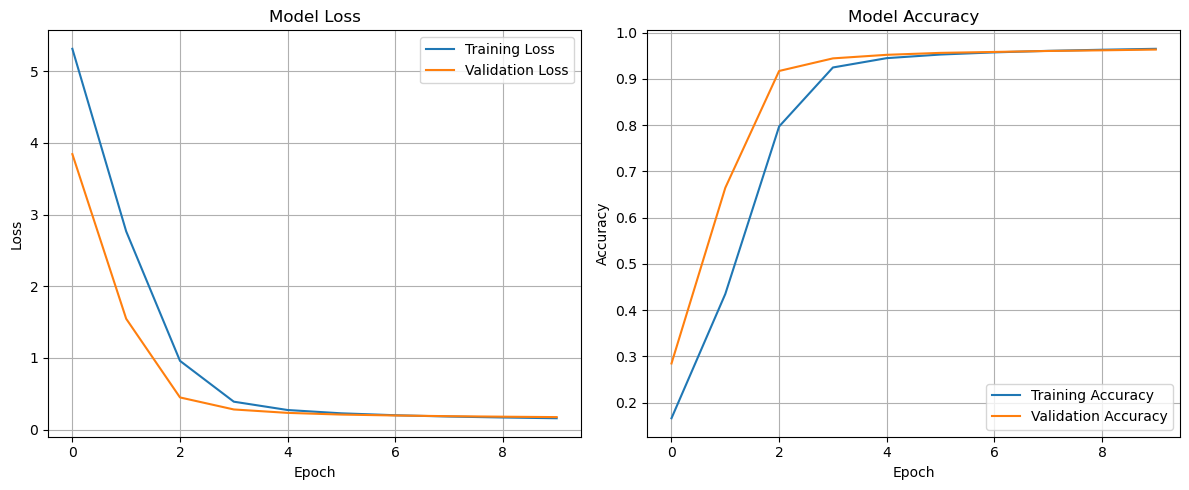

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0):
    """Generate text based on a prompt with proper lowercase handling."""
    # Convert prompt to lowercase to match training data
    lowercase_prompt = prompt#.lower()

    # Encode the prompt
    input_ids = sp.encode_as_ids(lowercase_prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

In [10]:
prompts = [
    "Frankenstein",
    "How slowly",
    "Monster",
    "Thus I relieve thee, my creator"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, sp, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: Frankenstein
Frankenstein. But I was not yet hasty in my hands, and I began to heat discontented and unsatisfied. Sir Isaac Newton is said to have avowed that he felt like a child picking up shells beside the great and unexplored ocean of truth. Those of his successors in each branch of natural philosophy with whom I was acquainted appeared even to my boy’s apprehensions as tyros engaged in the same pursuit. The untaught peasant beheld the elements around him and was acquainted with their practical uses. The most learned philosopher knew little more

Prompt: How slowly
How slowly to his desolation. Every night I was unable to secure him. As I looked upon the Swiss mountains and concealed my senses; I became an anxiety that preyed upon my wasted frame. Still, as I urged our leaving Ireland with such inquietude and impatience, my father thought it best to yield. We took our passage on board a vessel bound for Havre-de-Grace and sailed with a fair wind from the Irish shores. It w

In [11]:
# Cell 11: Load model (if you're starting a new session)
# Uncomment these lines to load a previously saved model
"""
# Load saved model
model = keras.models.load_model('frankenstein_model.keras')

# Load SentencePiece tokenizer
sp = spm.SentencePieceProcessor()
sp.load('frankensterin_sp.model')

# Test generation
prompt = "Mieleni minun tekevi"
generated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)
print(generated)
"""
 

'\n# Load saved model\nmodel = keras.models.load_model(\'frankenstein_model.keras\')\n\n# Load SentencePiece tokenizer\nsp = spm.SentencePieceProcessor()\nsp.load(\'frankensterin_sp.model\')\n\n# Test generation\nprompt = "Mieleni minun tekevi"\ngenerated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)\nprint(generated)\n'

### Hyperparameter experiments

Next the following configurations with different hyperparameters will be experimented with to evaluate the impact of model size, depth, and capacity on performance. The goal is to identify configurations that optimize the trade-off between computational efficiency and model expressivity.

| Model  | Embedding Dim | Heads | Layers | Feedforward Dim | Params     |
|--------|----------------|--------|--------|------------------|------------|
| Small  | 128            | 4      | 4      | 512              | 5,272,480  |
| Medium | 256            | 8      | 6      | 1024             | 11,314,208 |
| Large  | 512            | 8      | 8      | 2048             | 28,911,136 |


In [ ]:
# Build model from a config and helper to count params
import time
import pandas as pd
import matplotlib.pyplot as plt
from copy import deepcopy

# Function to build model from config
def build_model(config):
    embed_dim = config['embed_dim']
    num_heads = config['num_heads']
    ff_dim = config['ff_dim']
    num_layers = config['num_layers']

    inputs = keras.Input(shape=(seq_length,))
    embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)
    pos_encoding = get_positional_encoding(seq_length, embed_dim)
    x = embedding_layer + pos_encoding

    def create_causal_mask_tf(size):
        m = 1 - np.triu(np.ones((size, size)), k=1)
        return m

    for _ in range(num_layers):
        causal_mask = create_causal_mask_tf(seq_length)
        attention_output = keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=max(1, embed_dim // num_heads)
        )(x, x, attention_mask=causal_mask)
        x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)
        ffn = keras.Sequential([
            keras.layers.Dense(ff_dim, activation="relu"),
            keras.layers.Dense(embed_dim),
            keras.layers.Dropout(0.1)
        ])
        ffn_output = ffn(x)
        x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

    outputs = keras.layers.Dense(sp.get_piece_size())(x)
    model = keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])
    return model

# Helper to count parameters
def get_param_count(model):
    return model.count_params()


In [ ]:
# Define a small set of configurations to test
configs = [
    {'name': 'small',  'embed_dim':128, 'num_heads':2, 'num_layers':1, 'ff_dim':256},
    {'name': 'medium', 'embed_dim':256, 'num_heads':4, 'num_layers':2, 'ff_dim':512},
    {'name': 'large',  'embed_dim':512, 'num_heads':8, 'num_layers':4, 'ff_dim':1024},
]

# Train each model (for a reduced number of epochs to keep experiments quick)
exp_epochs = 4
exp_batch = 64

results = []
trained_models = {}
histories = {}

# Train models with different configurations
for config in configs:
    print('\nTraining config:', config['name'], config)
    model_config = deepcopy(config)
    model = build_model(model_config)
    param_count = get_param_count(model)

    start = time.time()      # Save start time

    # Train the model
    exp_history = model.fit(train_inputs, train_targets,
                     validation_data=(val_inputs, val_targets),
                     epochs=exp_epochs,
                     batch_size=exp_batch,
                     callbacks=[
                         keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
                     ],
                     verbose=1)
    
    
    end = time.time()      # Save end time  
    train_time = end - start        # Calculate training time


    # Calculate best validation loss
    best_val_loss = min(exp_history.history.get('val_loss', [float('nan')])) if exp_history is not None else float('nan')


    # Store results
    results.append({
        'Model': config['name'],
        'Config': config,
        'Params': param_count,
        'Train_Time_s': round(train_time, 2),
        'Best_Val_Loss': float(best_val_loss)
    })

    # Keep objects for later comparison
    trained_models[config['name']] = model
    histories[config['name']] = exp_history.history

# Create a results dataframe
results_df = pd.DataFrame(results).sort_values('Params')
results_df.reset_index(drop=True, inplace=True)
results_df



Training config: small {'name': 'small', 'embed_dim': 128, 'num_heads': 2, 'num_layers': 1, 'ff_dim': 256}
Epoch 1/4
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 872s 782ms/step - accuracy: 0.1414 - loss: 5.6575 - val_accuracy: 0.2369 - val_loss: 4.3877 - learning_rate: 3.0000e-04
Epoch 2/4
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 850s 764ms/step - accuracy: 0.2821 - loss: 3.8696 - val_accuracy: 0.3381 - val_loss: 3.3133 - learning_rate: 3.0000e-04
Epoch 3/4
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 841s 755ms/step - accuracy: 0.3998 - loss: 2.8921 - val_accuracy: 0.4786 - val_loss: 2.4023 - learning_rate: 3.0000e-04
Epoch 4/4
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 843s 757ms/step - accuracy: 0.5425 - loss: 2.0618 - val_accuracy: 0.6258 - val_loss: 1.6691 - learning_rate: 3.0000e-04

Training config: medium {'name': 'medium', 'embed_dim': 256, 'num_heads': 4, 'num_layers': 2, 'ff_dim': 512}
Epoch 1/4
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 1252s 1s/step - accuracy: 0.1804 - loss: 5.1618 - val_accuracy: 0.3009 - val_loss: 3.6738 - learn

,Model,Config,Params,Train_Time_s,Best_Val_Loss
0,small,"{'name': 'small', 'embed_dim': 128, 'num_heads...",5272480,3407.05,1.669061
1,medium,"{'name': 'medium', 'embed_dim': 256, 'num_head...",11314208,5164.46,0.309522
2,large,"{'name': 'large', 'embed_dim': 512, 'num_heads...",28911136,10747.72,2.328613


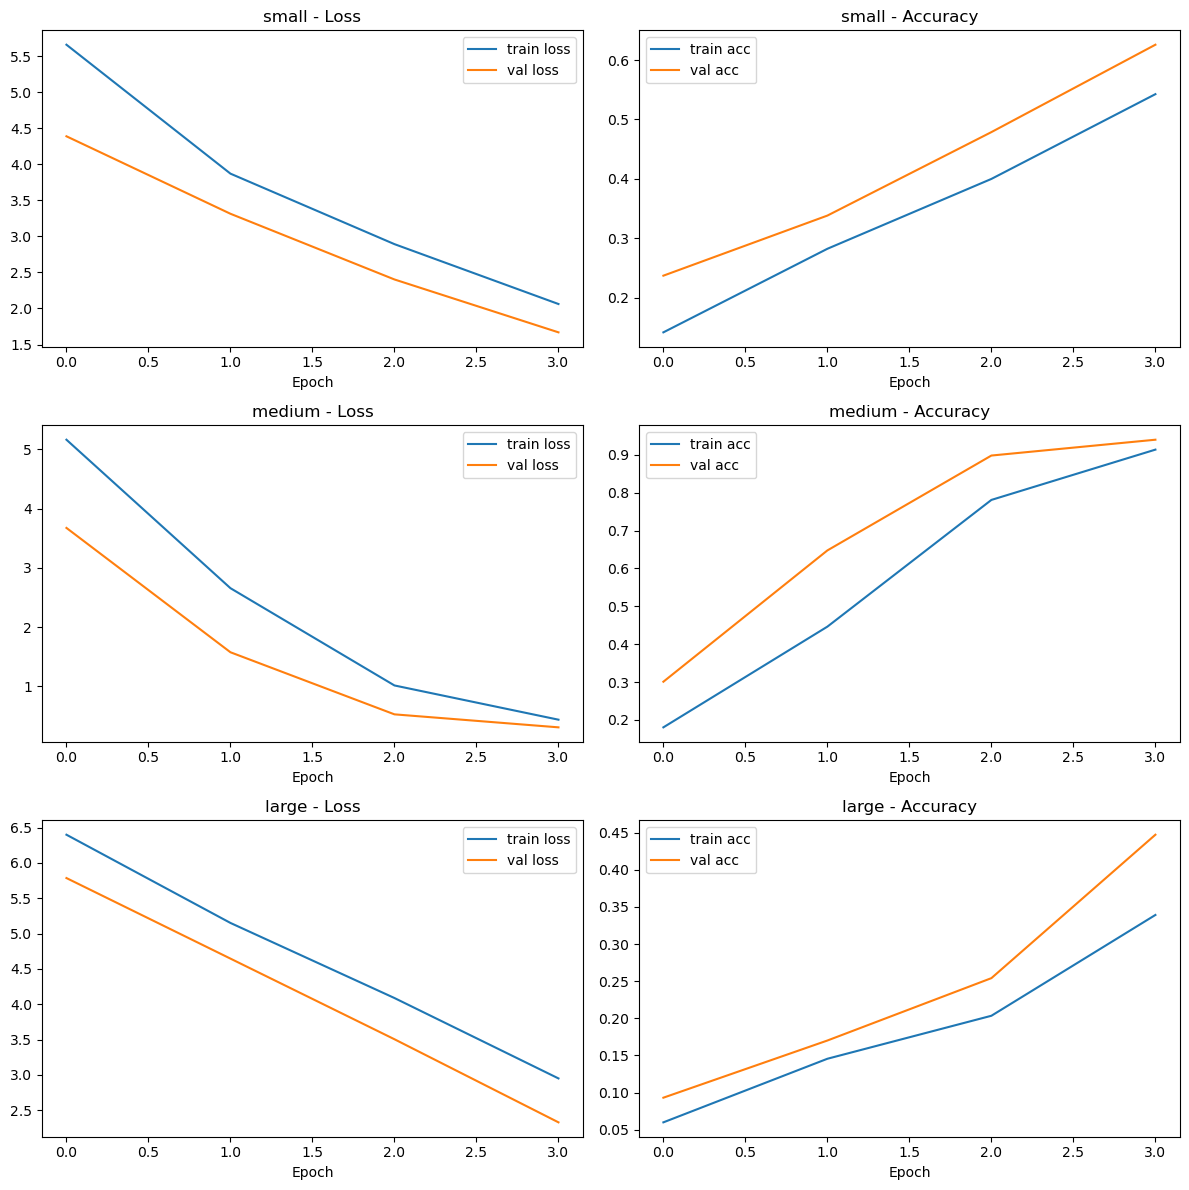

In [ ]:
# Plot loss/val_loss for each trained model
n = len(histories)
fig, axs = plt.subplots(n, 2, figsize=(12, 4*n))
if n == 1:
    axs = axs.reshape(1,2)
for i, (name, h) in enumerate(histories.items()):
    ax_loss = axs[i,0]
    ax_acc = axs[i,1]
    ax_loss.plot(h.get('loss', []), label='train loss')
    ax_loss.plot(h.get('val_loss', []), label='val loss')
    ax_loss.set_title(f'{name} - Loss')
    ax_loss.set_xlabel('Epoch')
    ax_loss.legend()

    ax_acc.plot(h.get('accuracy', []), label='train acc')
    ax_acc.plot(h.get('val_accuracy', []), label='val acc')
    ax_acc.set_title(f'{name} - Accuracy')
    ax_acc.set_xlabel('Epoch')
    ax_acc.legend()

plt.tight_layout()
plt.show()


**Small model** (5.2M params)
- Moderate training time (56 minutes) and reasonable validation loss of **1.67**.
- There might be some underfitting as it doesn't capture complex patterns.

**Medium model** (11.3M params)
- Best performance
- Validation drops dramatically to **0.3** which means better predictive accuracy for generation of the next token and stronger modeling capacity.
- Training time only moderately higher (86 minutes) but huge improvement in performance (loss reduced by 80%)

**Large model** (28.9M params)
- Longest training time, almost 3 hours (over twice the medium model).
- Validation loss becomes rises to **2.33** meaning that there is clearly overfitting.

We chose to use the medium model (except the num_layers we used was 3 instead of 2) as it is clearly the optimal model with best validation performance and moderate training time.


### Temperature experiments and generated examples

In [19]:
temperatures = [0.5, 1.0, 1.5]
test_prompt = 'Frankenstein'
num_gen_tokens = 120
gen_results = []

for model_name, model_obj in trained_models.items():
    print(f'\nGenerations for model: {model_name}')
    for temp in temperatures:
        out = generate_text(model_obj, sp, test_prompt, num_tokens=num_gen_tokens, temperature=temp)
        print('temperature: ', temp)
        print(out[:1000])
        gen_results.append({'model': model_name, 'temperature': temp, 'prompt': test_prompt, 'generated': out})

# Put results into a dataframe
gen_df = pd.DataFrame(gen_results)
gen_df.head()



Generations for model: small
temperature:  0.5
Frankenstein; but this was, I returned by a market-woman not, and gave up a companion to the power of his deliverer if he is almost of sorrow. I will seek for ever present, my dear girl, who love, and if you can do not be safe.” I had a few years of his eyes; I waited for the white plain work on you. But you must be my miserable wretch! I do not know that I am miserable; I have no one who would have been for so long a sacrifice of a little gossip concerning the room which the various voyages made of have written explanation
temperature:  1.0
Frankenstein; I replied the very destroyed by horror and despair. With this journey the heavens; I could with difficulty sit upright in which I felt. “My moments I was oppressed by fatigue, I must create another for the world, detracts from the work and author at an end. I traversed immense mountains and fixed on the fishermen having around; I, the courses of the rivers; but the woods, and the expirat

,model,temperature,prompt,generated
0,small,0.5,Frankenstein,"Frankenstein; but this was, I returned by a ma..."
1,small,1.0,Frankenstein,Frankenstein; I replied the very destroyed by ...
2,small,1.5,Frankenstein,"Frankenstein, but I will mercy of tapers, ther..."
3,medium,0.5,Frankenstein,Frankenstein. He could not sum to life. He cou...
4,medium,1.0,Frankenstein,Frankenstein. He could not solicit in honour i...


**Small model**

Produces fragmented and incoherent text. It also seems to be grammatically weak. It loses narrative structure quickly and becomes nonsense at higher temperatures.

- **Temperature 0.5**
    - Text is grammatically shaky but still resembles 19th-century literary tone.
    - Severe semantic drift and repetitive emotional statements.
    - Sentences collapse into run-ons and partial thoughts.

- **Temperature 1.0**
    - More chaos as the sentence structure breaks down quickly.
    - Emotional tone remains but phrases become nonsensical.
    - Narrative threads are lost.

- **Temperature 1.5**
    - Text becomes highly incoherent and surreal.
    - Disconnected images, contradictory phrases, and random insertions ("website").

--------------------------------------------

**Medium model**

Produces surprisingly coherent but often off-topic text especially at lower a temperature ("Project Gutenberg web pages"). At higher temperatures it maintains structure but becomes less semantically stable.

- **Temperature 0.5**
    - Very coherent, grammatical paragraphs.
    - The content drifts into Project Gutenberg donation text, indicating memorization.
    - It maintains tone and structure extremely well.

- **Temperature 1.0**
    - Mixes gothic/narrative tone and legal/compliance language
    - Structure (topic sentences, long paragraphs, grammatical consistency) remains good.
    - Occasionally confuses domains and victorian narrative blends into legal disclaimers.

- **Temperature 1.5**
    - Moderately coherent but more chaotic.
    - Stays stylistically appropriate (19th-century diction).
    - Unpredictable shifts between emotional narrative and off-topic statements.
-----------------------------------------------

**Large model**

Produces stylistically strong Frankenstein-like text but often mixes structural and formal text. Maintains tone and grammar but shows signs of overfitting to training data.

- **Temperature 0.5**
    - Very stylistically aligned with Frankenstein.
    - Strong grammar, descriptive imagery, and period-appropriate tone.
    - Once again sudden insertion of legal text.

- **Temperature 1.0**
    - Coherent gothic tone but there is some repetition, slightly disjointed logic and weird rhtorical questions.
    - Less copying of disclaimers but still some memorized structure.

- **Temperature 1.5**
    - Becomes verbose and dramatic but there is some logical breakdown, repeated emotional statements and fragmented metaphors.
    - Still maintains Frankenstein-like diction.






| Model | Coherence                  | Creativity                | Overfitting                               | Stability at High Temperature                  | Style Fidelity                   |
|-------|-----------------------------|----------------------------|--------------------------------------------|-------------------------------------------------|----------------------------------|
| Small | Poor                        | Low and often random       | Low                                         | Unstable; collapses at higher temperatures      | Weak stylistic consistency       |
| Medium| Strong                      | Moderate                   | High; reproduces training data at times    | Moderate stability                              | Good alignment with target style |
| Large | Good at low temperatures    | High                       | Very high; frequent memorization           | Poor stability at higher temperatures           | Excellent stylistic fidelity     |

Temperature controls randomness in text generation

- **0.5**: Deterministic, safe, but less creative

- **1.0**: Balanced, natural-sounding prose

- **1.5**: Highly creative, but prone to chaotic or incoherent text

### Final conclusion

The medium model proved to be the most balanced and effective configuration. It achieved the lowest validation loss, produced readable and stylistically appropriate text and maintained stability across a range of temperatures. While some overfitting occurred, it remained controlled and did not severely impact generation quality. The medium model demonstrated a strong ability to generalize from the training data without just reproducing it. 

### Use of AI

Ai was used mainly to help to make the conclusion table neat and help with plotting the hyperparameter experiments.